# 02 — Scaling: making 8 bits fit real tensors

Notebook 01 showed `float8_e4m3fn` only covers about **2⁻⁹ (0.002) … 448**, with ~6% worst-case rounding inside that
range, and silently clamps anything bigger. Real tensors don't respect that window. A **scale** moves the data into
the window before casting and back out afterwards:

```
encode:  x_fp8 = cast_fp8(x / scale)          scale = amax(|x|) / 448
decode:  x ≈ x_fp8 × scale                    (scale is stored next to the FP8 tensor, in FP32)
```

This notebook answers: what goes wrong without a scale, how *many* scales you need (granularity), how scales flow
through `F.scaled_mm` on MPS, and when to compute them (static vs dynamic).

In [1]:
from dataclasses import dataclass
from pathlib import Path
from typing import Literal

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

DEV = "mps" if torch.backends.mps.is_available() else "cpu"
E4 = torch.float8_e4m3fn
FP8_MAX = torch.finfo(E4).max  # 448
ST = F.ScalingType
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
IMG = ROOT / "docs" / "images"
IMG.mkdir(parents=True, exist_ok=True)
RECIPE_COLORS = {"none": "#c0392b", "tensorwise": "#f39c12", "rowwise": "#2e86de"}
print("torch", torch.__version__, "| device", DEV, "| FP8 max", FP8_MAX)


def save(fig: plt.Figure, name: str) -> None:
    fig.savefig(IMG / name, dpi=150, bbox_inches="tight")
    plt.show()

torch 2.15.0 | device mps | FP8 max 448.0


## 1. Three recipes

| Recipe | Scales | Shape of `scale` for `x: [M, K]` | Supported by `F.scaled_mm` on MPS |
|---|---|---|---|
| `none` | scale = 1 (just cast) | — | — |
| `tensorwise` | one per tensor | `[]` | ✅ `ScalingType.TensorWise` |
| `rowwise` | one per row | `[M, 1]` | ✅ `ScalingType.RowWise` |
| block-wise / MX | one per 32–128 elements | `[M, K/32]` | ❌ (CUDA/ROCm/XPU only) |

`amax` = the largest absolute value covered by the scale. Dividing by `amax / 448` maps that value exactly onto 448,
so **nothing can clamp**.

In [2]:
Recipe = Literal["none", "tensorwise", "rowwise"]


@dataclass(frozen=True)
class FP8Tensor:
    """FP8 values plus the FP32 decode scale needed to recover the original range.

    values: float8_e4m3fn, same shape as the input [M, K]
    scale:  float32, [] for tensorwise/none, [M, 1] for rowwise
    """

    values: torch.Tensor
    scale: torch.Tensor

    def dequantize(self) -> torch.Tensor:
        """Returns float32 [M, K]."""
        return self.values.float() * self.scale


def quantize(x: torch.Tensor, recipe: Recipe) -> FP8Tensor:
    """Quantize x [M, K] to FP8 with the given scaling recipe."""
    x = x.float()
    match recipe:
        case "none":
            amax = torch.tensor(FP8_MAX, device=x.device)
        case "tensorwise":
            amax = x.abs().amax()
        case "rowwise":
            amax = x.abs().amax(dim=-1, keepdim=True)
    scale = (amax / FP8_MAX).clamp(min=1e-12).float()
    return FP8Tensor((x / scale).to(E4), scale)


@dataclass(frozen=True)
class QuantStats:
    rel_err: float  # ||x̂ - x|| / ||x||
    flushed: float  # fraction of non-zero inputs that became 0
    clamped: float  # fraction of inputs beyond ±448 after scaling


def stats(x: torch.Tensor, q: FP8Tensor) -> QuantStats:
    x = x.float()
    xh = q.dequantize()
    return QuantStats(
        rel_err=((xh - x).norm() / x.norm()).item(),
        flushed=((xh == 0) & (x != 0)).float().mean().item(),
        clamped=((x / q.scale).abs() > FP8_MAX).float().mean().item(),
    )


x = torch.tensor([[0.001, 0.0035, 0.0072], [100.0, 300.0, 900.0]], device=DEV)
for r in ("none", "tensorwise", "rowwise"):
    q = quantize(x, r)
    print(f"{r:10s} scale={q.scale.flatten().tolist()}  decoded={q.dequantize().cpu().numpy().round(4).tolist()}")

none       scale=[1.0]  decoded=[[0.0020000000949949026, 0.0038999998942017555, 0.007799999788403511], [96.0, 288.0, 448.0]]
tensorwise scale=[2.0089285373687744]  decoded=[[0.0, 0.0038999998942017555, 0.007799999788403511], [96.42859649658203, 289.28570556640625, 900.0]]
rowwise    scale=[1.6071428035502322e-05, 2.0089285373687744]  decoded=[[0.0010000000474974513, 0.003599999938160181, 0.007199999876320362], [96.42859649658203, 289.28570556640625, 900.0]]


Even in this tiny example: `none` flushes the small row and clamps 900 → 448; `tensorwise` fixes the clamp but the
small row (≈1000x smaller than the big one) still gets flushed; `rowwise` gives each row its own window.

## 2. The problem: real tensors live far from [0.002, 448]

Three typical distributions. Gray = raw values; blue = after tensorwise scaling. Green band = FP8's normal range,
yellow = subnormals (fewer bits of precision), outside = lost.

tensor                                       recipe       rel err  flushed→0  clamped


LLM weights ~ N(0, 0.02)                     none           3.29%      3.88%    0.00%
LLM weights ~ N(0, 0.02)                     tensorwise     2.65%      0.00%    0.00%
activations ~ N(0, 1) + 0.2% outliers x300   none          21.83%      0.08%    0.02%
activations ~ N(0, 1) + 0.2% outliers x300   tensorwise     2.62%      0.15%    0.00%
gradients ~ N(0, 1e-4)                       none         100.00%    100.00%    0.00%


gradients ~ N(0, 1e-4)                       tensorwise     2.64%      0.00%    0.00%


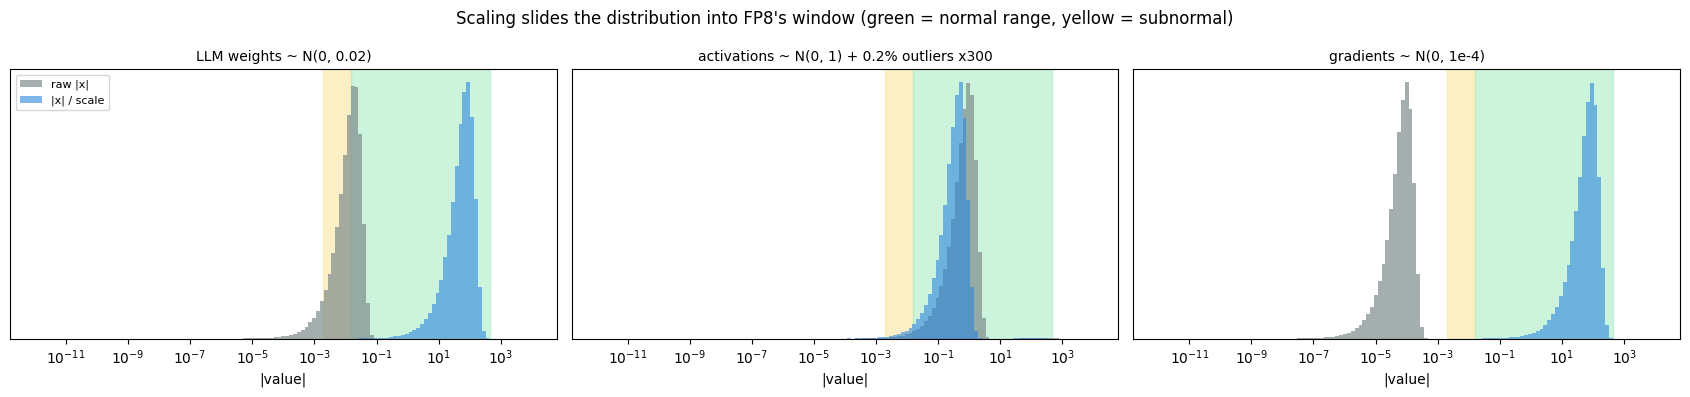

In [3]:
torch.manual_seed(0)
acts = torch.randn(512, 512, device=DEV)
acts[torch.rand_like(acts) < 0.002] *= 300  # rare large activations
examples = {
    "LLM weights ~ N(0, 0.02)": torch.randn(512, 512, device=DEV) * 0.02,
    "activations ~ N(0, 1) + 0.2% outliers x300": acts,
    "gradients ~ N(0, 1e-4)": torch.randn(512, 512, device=DEV) * 1e-4,
}
bins = np.logspace(-12, 4, 130)
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
print(f"{'tensor':44s} {'recipe':10s} {'rel err':>9s} {'flushed→0':>10s} {'clamped':>8s}")
for ax, (name, t) in zip(axes, examples.items(), strict=True):
    q = quantize(t, "tensorwise")
    ax.axvspan(2**-9, 2**-6, color="#f9e79f", alpha=0.6)
    ax.axvspan(2**-6, FP8_MAX, color="#abebc6", alpha=0.6)
    ax.hist(t.abs().flatten().cpu(), bins=bins, color="#7f8c8d", alpha=0.7, label="raw |x|")
    ax.hist((t / q.scale).abs().flatten().cpu(), bins=bins, color="#2e86de", alpha=0.6, label="|x| / scale")
    ax.set_xscale("log")
    ax.set_yticks([])
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("|value|")
    for r in ("none", "tensorwise"):
        s = stats(t, quantize(t, r))
        print(f"{name:44s} {r:10s} {s.rel_err:9.2%} {s.flushed:10.2%} {s.clamped:8.2%}")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Scaling slides the distribution into FP8's window (green = normal range, yellow = subnormal)")
fig.tight_layout()
save(fig, "02_scaling_shift.png")

Three different failure modes, one fix:
- **Gradients** are entirely below 2⁻⁹ → without a scale everything becomes 0 (100% error).
- **Activations** with outliers exceed 448 → without a scale the outliers clamp (~22% error from 0.02% of values).
- **Weights** sit in the subnormal band → without a scale they lose precision.

After scaling, all three land in the green band at the same ~2.6% error — FP8's built-in precision.

## 3. Granularity: when does one outlier ruin a shared scale?

The usual story (from INT8) is "one outlier squeezes everything else to zero, so use finer scales". FP8 is different:
it's **floating point**, so dividing by a big scale just shifts exponents — relative precision is unchanged *until the
small values drop below FP8's normal range*. That range spans 448 / 2⁻⁶ ≈ **28,672x**.

Experiment: `[256 tokens x 1024 channels]` of N(0, 1), inject an outlier of growing size, and measure the error on
**all the other (normal) values** — the ones the outlier might hurt.
- **row outlier**: one token is huge (rowwise scaling can isolate it)
- **channel outlier**: one hidden dim is huge in *every* token (rowwise can't isolate it)
- **INT8 tensorwise** for comparison: uniform steps of `amax / 127`

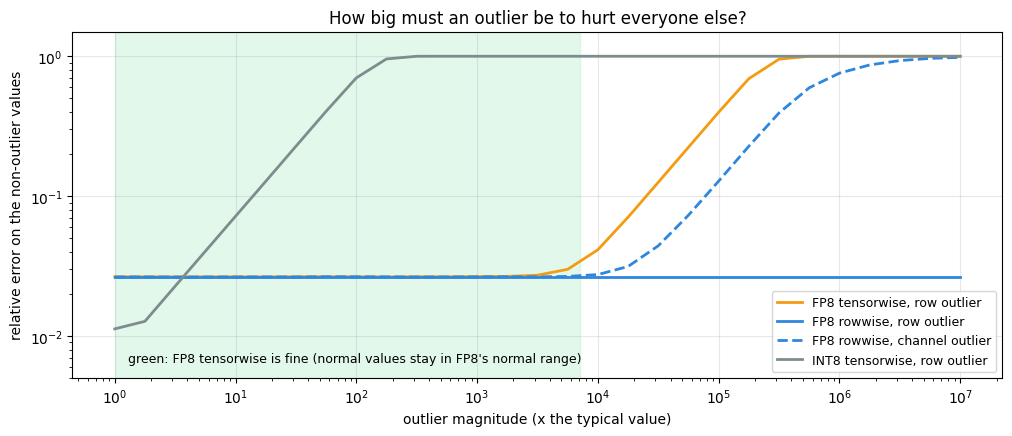

FP8 tensorwise, row outlier    {'1e+00': '2.7%', '6e+01': '2.7%', '3e+03': '2.7%', '2e+05': '69.1%', '1e+07': '100.0%'}
FP8 rowwise, row outlier       {'1e+00': '2.6%', '6e+01': '2.6%', '3e+03': '2.6%', '2e+05': '2.6%', '1e+07': '2.6%'}
FP8 rowwise, channel outlier   {'1e+00': '2.6%', '6e+01': '2.7%', '3e+03': '2.6%', '2e+05': '22.7%', '1e+07': '98.2%'}
INT8 tensorwise, row outlier   {'1e+00': '1.1%', '6e+01': '40.4%', '3e+03': '100.0%', '2e+05': '100.0%', '1e+07': '100.0%'}


In [4]:
def int8_tensorwise(x: torch.Tensor) -> torch.Tensor:
    """Symmetric INT8 round-trip with one scale; returns float32 with x's shape."""
    s = x.abs().amax() / 127
    return (x / s).round().clamp(-127, 127) * s


def outlier_case(kind: Literal["row", "channel"], factor: float) -> tuple[torch.Tensor, torch.Tensor]:
    """Returns (x [256, 1024], mask of non-outlier elements [256, 1024])."""
    g = torch.Generator(device="cpu").manual_seed(1)
    x = torch.randn(256, 1024, generator=g)
    normal = torch.ones_like(x, dtype=torch.bool)
    match kind:
        case "row":
            x[7] *= factor
            normal[7] = False
        case "channel":
            x[:, 3] *= factor
            normal[:, 3] = False
        case _:
            raise AssertionError(kind)
    return x.to(DEV), normal.to(DEV)


def err_on_normal(x: torch.Tensor, xh: torch.Tensor, normal: torch.Tensor) -> float:
    return ((xh - x)[normal].norm() / x[normal].norm()).item()


lines = {
    "FP8 tensorwise, row outlier": ("row", lambda x: quantize(x, "tensorwise").dequantize(), "#f39c12", "-"),
    "FP8 rowwise, row outlier": ("row", lambda x: quantize(x, "rowwise").dequantize(), "#2e86de", "-"),
    "FP8 rowwise, channel outlier": ("channel", lambda x: quantize(x, "rowwise").dequantize(), "#2e86de", "--"),
    "INT8 tensorwise, row outlier": ("row", int8_tensorwise, "#7f8c8d", "-"),
}
factors = np.geomspace(1, 1e7, 29)
curves = {name: [] for name in lines}
for f in factors:
    for name, (kind, roundtrip, _, _) in lines.items():
        x, normal = outlier_case(kind, float(f))
        curves[name].append(err_on_normal(x, roundtrip(x), normal))

fig, ax = plt.subplots(figsize=(12, 4.5))
for name, (_, _, color, ls) in lines.items():
    ax.plot(factors, np.minimum(curves[name], 1.0), ls, color=color, lw=2, label=name)
ax.axvspan(1, 448 / 2**-6 / 4, color="#abebc6", alpha=0.35)
ax.text(1.3, 0.0065, "green: FP8 tensorwise is fine (normal values stay in FP8's normal range)", fontsize=9)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_ylim(5e-3, 1.5)
ax.set_xlabel("outlier magnitude (x the typical value)")
ax.set_ylabel("relative error on the non-outlier values")
ax.set_title("How big must an outlier be to hurt everyone else?")
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.3)
save(fig, "02_outlier_sweep.png")

for name in lines:
    at = {f"{f:.0e}": f"{curves[name][i]:.1%}" for i, f in enumerate(factors) if i % 7 == 0}
    print(f"{name:30s} {at}")

What this shows:
- **INT8** (gray) is actually *better* on clean data (~1.1% vs ~2.6%: 255 evenly spaced steps beat 8 per octave),
  but collapses fast — a ~60x outlier already costs ~40% error on everything else.
- **FP8 tensorwise** (orange) is flat at FP8's ~2.6% up to ~3,000x, then normal values fall into
  subnormals and finally flush to zero. Realistic LLM activation outliers (~10–1000x) are mostly inside the safe zone.
- **FP8 rowwise** isolates a row outlier completely — flat at any size.
- A **channel** outlier lives in every row, so rowwise behaves like tensorwise. Fixing that needs per-block scales
  (MX formats, not on MPS) or SmoothQuant-style rebalancing into the weights.

So on FP8, rowwise is insurance against **extreme** dynamic range, not a must-have for typical outliers.

## 4. Scales inside `F.scaled_mm` on MPS

`F.scaled_mm` takes the FP8 matrices **and** their decode scales and computes
`(A_fp8 · scale_a) @ (B_fp8 · scale_b)` with FP32 accumulation, returning BF16. Scales never touch the FP8 values —
they're applied to the accumulated result, which is why the per-row (`[M,1]`) and per-column (`[1,N]`) shapes work.

A linear layer `y = x @ Wᵀ`: activations `x: [M, K]`, weights `W: [N, K]` → `scale_a: [M, 1]`, `scale_b: [1, N]`.

BF16 matmul          relative error vs FP32 =    0.266%
FP8 none             relative error vs FP32 =   67.035%
FP8 tensorwise       relative error vs FP32 =    3.612%
FP8 rowwise          relative error vs FP32 =    3.614%
FP8 forgot scales    relative error vs FP32 = 65606.708%

native vs emulated max |diff| / max|y| = 1.88e-06


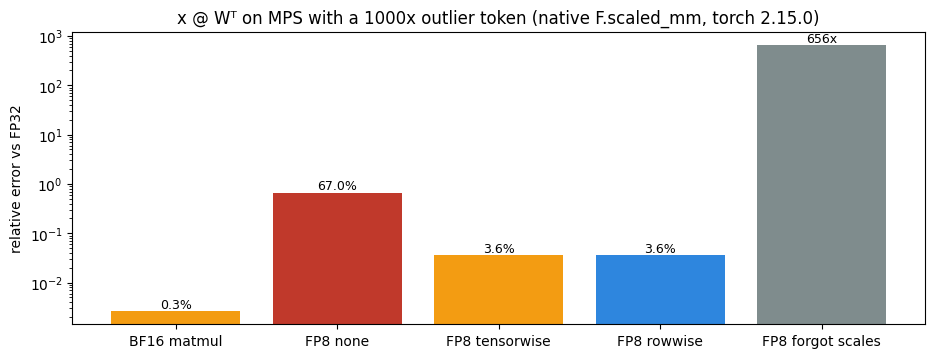

In [5]:
torch.manual_seed(0)
X, _ = outlier_case("row", 1000.0)  # [256, 1024], one 1000x token
W = torch.randn(512, 1024, device=DEV) * 0.02  # [N=512, K=1024]
ref = X @ W.t()  # FP32 reference [256, 512]


def rel(y: torch.Tensor) -> float:
    return ((y.float() - ref).norm() / ref.norm()).item()


def fp8_linear(x: torch.Tensor, w: torch.Tensor, recipe: Recipe) -> torch.Tensor:
    """y = x @ wᵀ via native F.scaled_mm. x: [M, K], w: [N, K] -> [M, N] bf16."""
    qx, qw = quantize(x, recipe), quantize(w, recipe)
    match recipe:
        case "rowwise":  # scales: x [M, 1], w [1, N]
            return F.scaled_mm(qx.values, qw.values.t(), qx.scale, ST.RowWise, qw.scale.reshape(1, -1), ST.RowWise)
        case _:  # "tensorwise" | "none": scalar scales
            return F.scaled_mm(qx.values, qw.values.t(), qx.scale, ST.TensorWise, qw.scale, ST.TensorWise)


qx, qw = quantize(X, "tensorwise"), quantize(W, "tensorwise")
one = torch.tensor(1.0, device=DEV)
results = {
    "BF16 matmul": rel(X.bfloat16() @ W.bfloat16().t()),
    "FP8 none": rel(fp8_linear(X, W, "none")),
    "FP8 tensorwise": rel(fp8_linear(X, W, "tensorwise")),
    "FP8 rowwise": rel(fp8_linear(X, W, "rowwise")),
    "FP8 forgot scales": rel(F.scaled_mm(qx.values, qw.values.t(), one, ST.TensorWise, one, ST.TensorWise)),
}
for k, v in results.items():
    print(f"{k:20s} relative error vs FP32 = {v:9.3%}")
# rowwise ≈ tensorwise here: a 1000x outlier is inside FP8's safe zone (section 3)

# sanity: native kernel == dequantize-then-matmul (same math, different execution)
emulated = (qx.dequantize() @ qw.dequantize().t()).bfloat16()
native = fp8_linear(X, W, "tensorwise")
print(
    f"\nnative vs emulated max |diff| / max|y| = {((native - emulated).abs().max() / emulated.abs().max()).item():.2e}"
)

fig, ax = plt.subplots(figsize=(11, 3.8))
colors = ["#f39c12", RECIPE_COLORS["none"], RECIPE_COLORS["tensorwise"], RECIPE_COLORS["rowwise"], "#7f8c8d"]
bars = ax.bar(results.keys(), results.values(), color=colors)
ax.bar_label(bars, labels=[f"{v:.1%}" if v < 10 else f"{v:,.0f}x" for v in results.values()], fontsize=9)
ax.set_yscale("log")
ax.set_ylabel("relative error vs FP32")
ax.set_title(f"x @ Wᵀ on MPS with a 1000x outlier token (native F.scaled_mm, torch {torch.__version__})")
save(fig, "02_scaled_mm_error.png")

"Forgot scales" is the classic bug: the FP8 bytes are right but decoded with scale 1, so the result is off by
`1 / (scale_a · scale_b)`. The scale is part of the tensor — always carry it with the values.

## 5. When to compute the scale: static vs dynamic

- **Static**: measure `amax` once on calibration data, then reuse the scale. Free at runtime, ideal for **weights**.
- **Dynamic**: recompute `amax` every call. Costs a reduction per call (notebook 01 showed this overhead on MPS),
  but adapts to the input — safer for **activations**.

Below, a static scale is calibrated on N(0, 1) data, then the input distribution drifts.

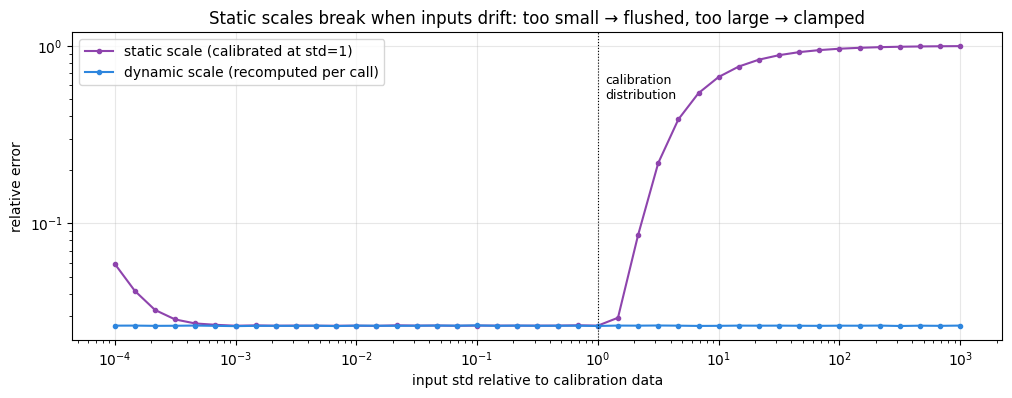

static clamps 99.6% of values at 1000x drift


In [6]:
torch.manual_seed(0)
calib = torch.randn(256, 1024, device=DEV)
static_scale = calib.abs().amax() / FP8_MAX
drift = np.geomspace(1e-4, 1e3, 43)
static_err, dynamic_err, static_clamped = [], [], []
for d in drift:
    x = torch.randn(256, 1024, device=DEV) * float(d)
    s = stats(x, FP8Tensor((x / static_scale).to(E4), static_scale))
    static_err.append(s.rel_err)
    static_clamped.append(s.clamped)
    dynamic_err.append(stats(x, quantize(x, "tensorwise")).rel_err)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(drift, static_err, "o-", ms=3, color="#8e44ad", label="static scale (calibrated at std=1)")
ax.plot(drift, dynamic_err, "o-", ms=3, color="#2e86de", label="dynamic scale (recomputed per call)")
ax.axvline(1.0, color="k", ls=":", lw=0.8)
ax.text(1.15, 0.5, "calibration\ndistribution", fontsize=9)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("input std relative to calibration data")
ax.set_ylabel("relative error")
ax.set_title("Static scales break when inputs drift: too small → flushed, too large → clamped")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
save(fig, "02_static_vs_dynamic.png")
print(f"static clamps {static_clamped[-1]:.1%} of values at {drift[-1]:.0f}x drift")

## Findings

| Question | Answer (measured on MPS, torch 2.15) |
|---|---|
| Why scale at all? | FP8's window is 0.002 … 448. Gradients fall below it (→ 0), outliers above it (→ clamp), weights in the low-precision subnormal band. |
| How many scales? | FP8 tolerates outliers far better than INT8: tensorwise is fine until an outlier is ~10³–10⁴x the typical value. **Rowwise** isolates row/token outliers of any size. Channel outliers need block-wise scaling (not on MPS) or SmoothQuant-style rebalancing. |
| How do scales reach the matmul? | Pass them to `F.scaled_mm` (`[]` tensorwise, `[M,1]`/`[1,N]` rowwise); they're applied after FP32 accumulation. Native result matches dequantize-then-matmul. |
| When to compute them? | Static for weights (free); dynamic for activations (robust, costs an `amax` per call). |
| Does PyTorch do this automatically? | No — `.to(fp8)` just clamps. You (or a library like torchao) must compute and carry scales. |